In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
!pip install micrograd

In [3]:
from micrograd.engine import Value

In [4]:
a = Value(-4.0)
b = Value(2.0)

In [5]:
a

Value(data=-4.0, grad=0)

Micrograd is a Scalar Valued Autograd Engine. So, it works on level of Individual Scalars like -4 and 2.<br>
We are taking Neural nets and breaking them down to these atoms of individual Scalars, all the little pluses and times and all of this is excessive.<br>

It's done for Pedagogical (learning) reasons, so that you avoid having to deal with n-dimensional tensors that you deal with in Modern Deep Neural Network Libraries

Derivateies in Python will fail if dx is made 0.00000000001 or something very small similar to this.<br>
This is because of Floating Point Arithmetic in Computers breaks down as we represent them using finite memory.

In [6]:
class Value:
  def __init__(self, data, _children=(), _op='', label = ''):
    self.data = data
    self.grad = 0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad

    out._backward = _backward # Stored in a closure.

    return out

  def __mul__(self, other):
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward

    return out

  def tanh(self):
    x = self.data
    t = (np.exp(2*x) - 1) / (np.exp(2*x) + 1)
    out = Value(t, (self,), 'tanh')

    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward

    return out

  def backward(self):
    topo = []
    visited = set()
    def build_topo(v):
        if v not in visited:
            visited.add(v)
            for child in v._prev:
                build_topo(child)
            topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
        node._backward()

    return None

When we have no _children, we are missing the connective tissue of this graph. We want to know and keep pointers about what values produce what other values.<br>
So he created an empty tuple called _children. And a different variable within the class called _prev, which will be the set of children.<br>

For new values, it does not have any history/children, but when we are creating new values through addition or multiplication, we can assign the operands to this _children, so we can keep track of what operands caused this result<br>

We now know what operands created this value, but we don't know what operator created this value, so we add _op.


In [8]:
a = Value(2.0, label = 'a')
b = Value(-3.0, label = 'b')
c = Value(10.0, label = 'c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label = 'f')
L = d * f; L.label = 'L'

In [14]:
L._prev

{Value(data=-2.0), Value(data=4.0)}

In [17]:
d._op

'+'

These expressions are going to get quite a bit larger, so we will need a nice way to visualize thexe expressions we are building out.

In [16]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label= "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

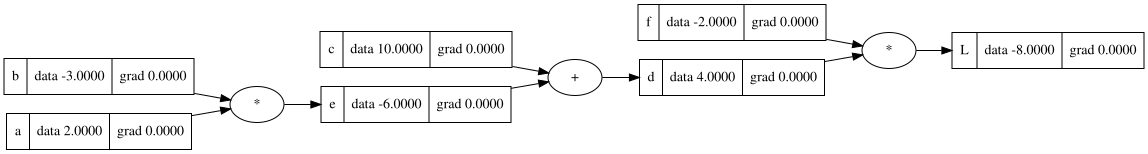

In [18]:
draw_dot(L)

## 🔁 Gradient Flow Through a **Plus (+) Node** in Backpropagation

The **plus node** simply **routes the gradient backward** to its input nodes.

---

### 🧮 Chain Rule Expansion

If we want to compute:

$$
\frac{dL}{dc}
$$

Using the chain rule:

$$
\frac{dL}{dc} = \frac{dL}{dd} \cdot \frac{dd}{dc}
$$

---

### ➕ Local Gradient of an Addition Node

Given the forward operation:

$$
d = c + e
$$

The local derivative is:

$$
\frac{dd}{dc} = 1.0
$$

So:

$$
\frac{dL}{dc} = \frac{dL}{dd} \cdot 1.0 = \frac{dL}{dd}
$$

This means the gradient flowing into **c** is **exactly the gradient at d**.

Similarly:

$$
\frac{dL}{de} = \frac{dL}{dd}
$$

---

### 🧠 Backpropagation Intuition

- In backpropagation, we start computing gradients from the **final layer** and move **backward layer by layer**
- Each node passes gradients to its inputs using the chain rule
- A `+` node **does not modify the gradient** — it simply **copies and distributes it to both input nodes recursively**

---

### 📌 Key Takeaway

A plus node acts only as a **gradient distributor**, passing the incoming gradient unchanged to all nodes that contributed to the sum.

---

### 🧩 Summary Table

| Operation | Local Derivative | Gradient Behavior |
|----------|----------------|------------------|
| `d = c + e` | `∂d/∂c = 1`, `∂d/∂e = 1` | Gradient is **copied to both inputs without change** |


In [19]:
def lol():
  h = 0.0001
  a = Value(2.0, label = 'a')
  b = Value(-3.0, label = 'b')
  c = Value(10.0, label = 'c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label = 'f')
  L = d * f; L.label = 'L'
  L1 = L.data

  a = Value(2.0 + h, label = 'a')
  b = Value(-3.0, label = 'b')
  c = Value(10.0, label = 'c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label = 'f')
  L = d * f; L.label = 'L'
  L2 = L.data

  print((L2 - L1)/h)
lol()

6.000000000021544


We found dL/da above, but here Karpathy is interested to know all the derivatives as well.<br>

So, we can find all of those by either calculating the derivative expression in out head and putting in the value or actually using the drivative definition to nudel certain values slightly and calculate: <br>
(f(x+h)- f(x))/ h.

In [ ]:
# All of the below are manually calculated by doing dL/dd, dL/dd, dL/df ,dL/de, dL/dc, etc
# For example - dL/db = (dL/dd) * (dd/de) * (de/db) OR (dL/de) * (de/db) if dL/de is known.
L.grad = 1.0
d.grad = -2.0
f.grad = 4.0
c.grad = -2.0
e.grad = -2.0
b.grad = -2.0*2.0
a.grad = -2.0*-3.0

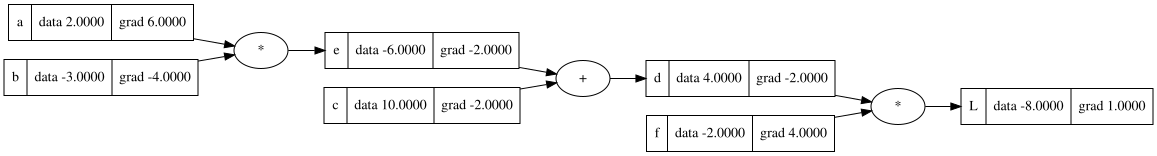

In [ ]:
draw_dot(L)

### Backpropagation is the recusrsive application of the chain rule, backwards through the computation graph.

Once the gradients are calculated, now we want to nudge our inputs like a and b to make L go up.

If we want L to go up we want to go in the direction of the gradient.

We have to nudge each value in the direction of the gradient, to make the final variable L, go up.
We should do this nudging for the independent variables.

In [ ]:
a.data += 0.01 *a.grad
b.data += 0.01 *b.grad
c.data += 0.01 *c.grad
f.data += 0.01 *f.grad

e = a * b
d = e + c
L = d * f


# Because we have nudged the independent variables slightly, we expect the dependent variables to slightly go up.
print(L.data)


-7.286496


It did go up as expected. From -8.0 to -7.28<br>
This is one step of the optimization that we are running.

Activation Functions will squash the input to a particular range. <br>
For example, tanh, will squish the output between -1 and +1

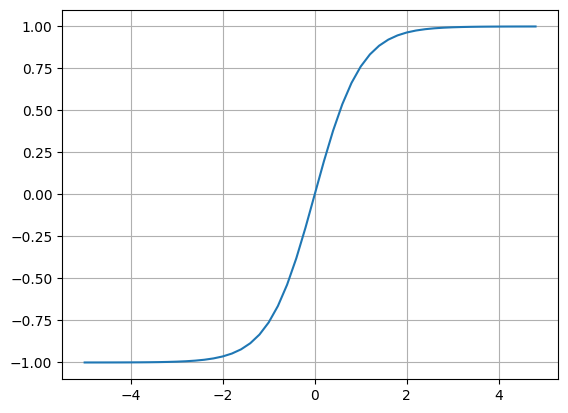

In [ ]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2))); plt.grid();

In [ ]:
#inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
#weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
#bias b
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

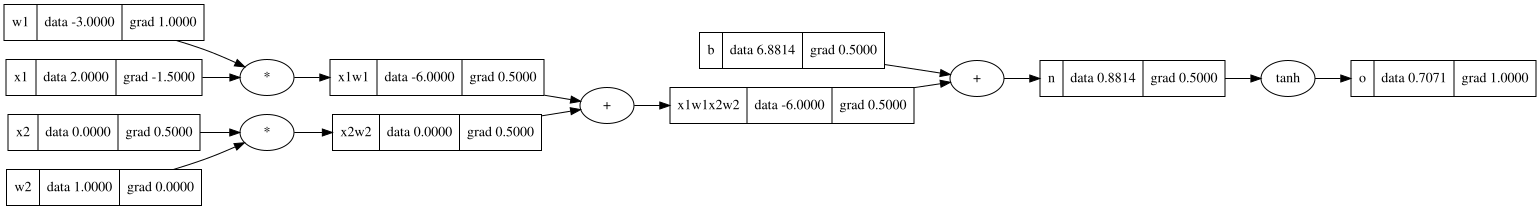

In [ ]:
draw_dot(o)

We need to find what is the derivatinve of o wrt inputs. In a neural network setting, we typically care about the derivatives of o wrt weights, w2 and w1

In [ ]:
# Manually setting Grdients
o.grad = 1.0
n.grad = 0.5 # This is because derivative of tanh is 1- tanh^2(x), and 1 - 0.7071**2 = 1 - 0.7071**2

x1w1x2w2.grad = 0.5
b.grad = 0.5

x1w1.grad = 0.5
x2w2.grad = 0.5

x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

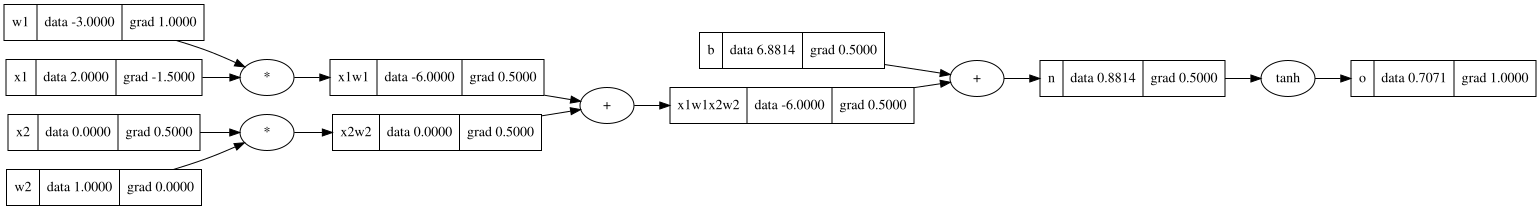

In [ ]:
draw_dot(o)

In [ ]:
# Automating gradient assigning
o.grad = 1.0
o._backward()

In [ ]:
n._backward()

In [ ]:
x1w1x2w2._backward()

In [ ]:
x1w1._backward()
x2w2._backward()
x1._backward()
w1._backward()
x2._backward()
w2._backward()

This is not completely automatic because we are having to call `._backward()` on every node manually<br>
So, we have to automate the calling of this function.<br>
We have laid out the mathematical expression and now we are going backwards through this expression.<br>

Going backwards through this expression means we never want to call `._backward()` before we have done the `._backward()` for everything after it.
We have to get its full dependencies, before calling `._backward()` on any particular node. The dependencies here mean the gradient of the node that comes after it.<br>

This ordering of graphs can be achieved using something called **Topological Sort**

Topological Sort means laying out the graph in such a way that all the edges go from left to right.

In [ ]:
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-6.0),
 Value(data=6.881373587019543),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [ ]:
o.grad = 1.0
for node in reversed(topo):
    node._backward()

In [ ]:
o.backward()

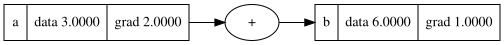

In [ ]:
 # A bug that arises in cases where same node is used multiple times

 a = Value(3.0, label='a')
 b = a + a; b.label = 'b'
 b.backward()
 draw_dot(b)

  Here, originally, `self.grad = 1.0 * out.grad` and `other.grad = 1.0 * out.grad`. So, when the node is the same, one of these statements will overwrite the other.

    def _backward():
      self.grad = 1.0 * out.grad
      other.grad = 1.0 * out.grad
    out._backward = _backward

Ideally, we would want the gradients to be added up. This is according to multivariate calculus. So, we change the `=` to `+=`

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward

After this, the gradient is calculated correctly as 2.0 instead of 1.0

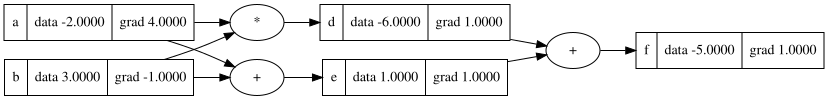

In [ ]:
a = Value(-2.0, label='a')
b = Value(3.0, label='b')

d = a * b; d.label = 'd'
e = a + b; e.label = 'e'
f = d + e; f.label = 'f'

f.backward()

draw_dot(f)